In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el pequeño proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta. Resuélvalo completamente a mano, anotando cada operación, antes de comprobarlo con la librería.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT y enumere todas las rutas desde el inicio hasta el final con su duración. ¿Cuál es la duración del proyecto y cuál la ruta crítica?  "
pregunta_2 = "2. Calcule, por el paso hacia adelante, el inicio y fin más tempranos de cada actividad; por el paso hacia atrás, el fin e inicio más tardíos.  "
pregunta_3 = "3. Calcule las holguras total, libre e independiente de cada actividad escribiendo la fórmula con los números sustituidos.  "
pregunta_4 = "4. La actividad B tiene holgura total mayor que la libre. Explique con las fechas de sus sucesoras por qué.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y enumere todas las rutas desde el inicio hasta el final con su duración. ¿Cuál es la duración del proyecto y cuál la ruta crítica?  

2. Calcule, por el paso hacia adelante, el inicio y fin más tempranos de cada actividad; por el paso hacia atrás, el fin e inicio más tardíos.  

3. Calcule las holguras total, libre e independiente de cada actividad escribiendo la fórmula con los números sustituidos.  

4. La actividad B tiene holgura total mayor que la libre. Explique con las fechas de sus sucesoras por qué.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 5       ),
    ('B'     , '---'      , 6       ),
    ('C'     , 'B'        , 4       ),
    ('D'     , 'A'        , 6       ),
    ('E'     , 'C,D'      , 8       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,5
B,---,6
C,B,4
D,A,6
E,"C,D",8


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y enumere todas las rutas desde el inicio hasta el final con su duración. ¿Cuál es la duración del proyecto y cuál la ruta crítica?  

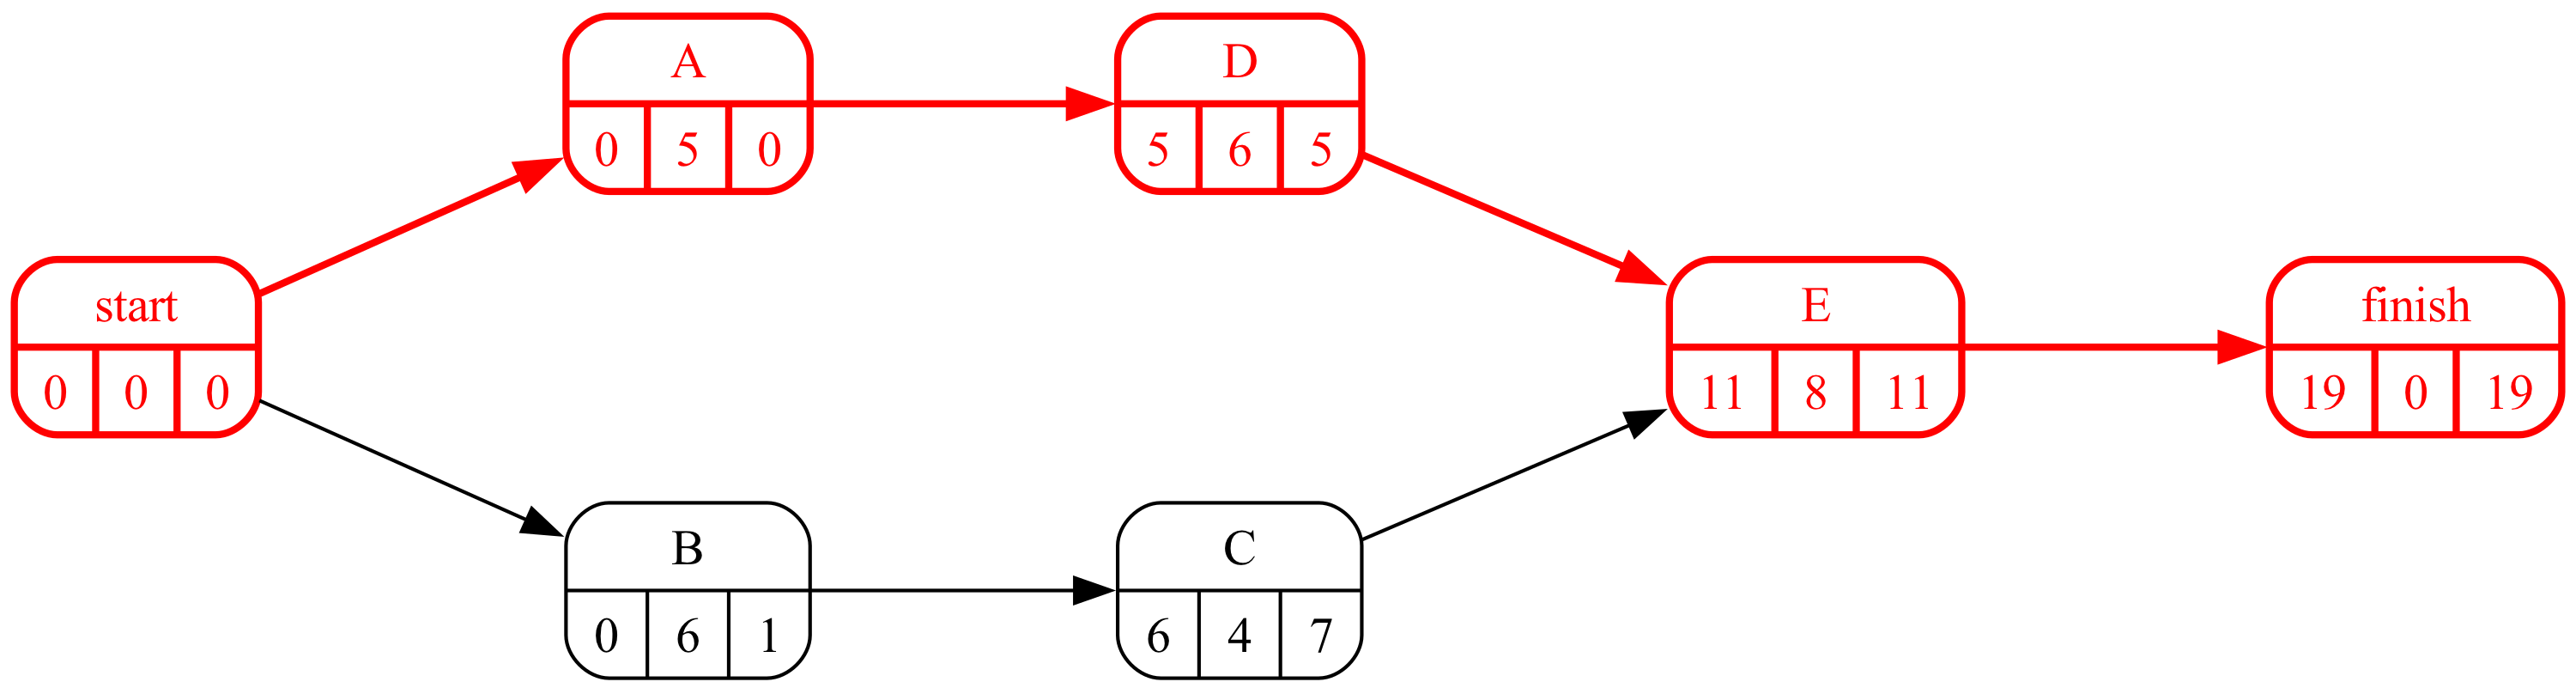

In [9]:
#| fig-cap: "Grafo Roy"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [10]:
#| tbl-cap: "Rutas del proyecto y su duración"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
detalle_rutas(R, datos_proyecto['duration'][R.columns])

,actividades,duración = suma,duración
Route_1,A - D - E,A(5) + D(6) + E(8) = 19,19.0
Route_2,B - C - E,B(6) + C(4) + E(8) = 18,18.0


In [11]:
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'La duración del proyecto es la de la ruta más larga: {duracion_proyecto} días.')

- Route_1 :	A, D, E <br> 

La duración del proyecto es la de la ruta más larga: 19 días.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Calcule, por el paso hacia adelante, el inicio y fin más tempranos de cada actividad; por el paso hacia atrás, el fin e inicio más tardíos.  

Paso hacia adelante (de izquierda a derecha): ES = máximo de los EF de las predecesoras (0 si es inicial); EF = ES + duración. Paso hacia atrás (de derecha a izquierda): LF = mínimo de los LS de las sucesoras (la duración del proyecto si es final); LS = LF − duración.

In [13]:
#| tbl-cap: "Paso hacia adelante y hacia atrás"
#| label: tbl-pasos
calendario = proyecto.calendar(datos_proyecto['duration'])
detalle = detalle_holguras(calendario, prelaciones)
detalle[['ES = máx EF pred.', 'EF = ES + d', 'LF = mín LS suc.', 'LS = LF − d']]

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d
actividad,,,,
A,inicial → 0,0 + 5 = 5,mín(D: 5) = 5,5 − 5 = 0
B,inicial → 0,0 + 6 = 6,mín(C: 7) = 7,7 − 6 = 1
C,máx(B: 6) = 6,6 + 4 = 10,mín(E: 11) = 11,11 − 4 = 7
D,máx(A: 5) = 5,5 + 6 = 11,mín(E: 11) = 11,11 − 6 = 5
E,"máx(C: 10, D: 11) = 11",11 + 8 = 19,final → 19,19 − 8 = 11


## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Calcule las holguras total, libre e independiente de cada actividad escribiendo la fórmula con los números sustituidos.  

In [15]:
#| tbl-cap: "Holguras con los números sustituidos"
#| label: tbl-holgurasPaso
detalle[['H_total = LS − ES', 'H_libre = mín ES suc. − EF', 'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)']]

,H_total = LS − ES,H_libre = mín ES suc. − EF,"H_indep. = máx(0, mín ES suc. − máx LF pred. − d)"
actividad,,,
A,0 − 0 = 0,5 − 5 = 0,"máx(0, 5 − 0 − 5) = 0"
B,1 − 0 = 1,6 − 6 = 0,"máx(0, 6 − 0 − 6) = 0"
C,7 − 6 = 1,11 − 10 = 1,"máx(0, 11 − 7 − 4) = 0"
D,5 − 5 = 0,11 − 11 = 0,"máx(0, 11 − 5 − 6) = 0"
E,11 − 11 = 0,19 (fin) − 19 = 0,"máx(0, 19 − 11 − 8) = 0"


In [16]:
#| tbl-cap: "Calendario y holguras según la librería"
#| label: tbl-calendario
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,5,5,0,0,0,5
B,0,1,6,7,0,0,1,6
C,6,7,10,11,1,0,1,4
D,5,5,11,11,0,0,0,6
E,11,11,19,19,0,0,0,8


## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. La actividad B tiene holgura total mayor que la libre. Explique con las fechas de sus sucesoras por qué.  

In [18]:
X = 'B'
sucesoras_X = [a for a, ps in prelaciones.immediate_predecessor.items() if X in ps]
Markdown(f'''{X} termina lo más pronto en {int(calendario.loc[X, "fin_mas_temprano"])} y sus sucesoras ({", ".join(sucesoras_X)}) empiezan lo más pronto en {int(calendario.loc[sucesoras_X, "inicio_mas_temprano"].min())}: eso limita su holgura libre a {int(calendario.loc[X, "H_libre"])}. Pero las sucesoras pueden empezar lo más tarde en {int(calendario.loc[sucesoras_X, "inicio_mas_tardio"].min())}, así que {X} puede retrasarse hasta {int(calendario.loc[X, "H_total"])} si arrastra a sus sucesoras (holgura total).''')

B termina lo más pronto en 6 y sus sucesoras (C) empiezan lo más pronto en 6: eso limita su holgura libre a 0. Pero las sucesoras pueden empezar lo más tarde en 7, así que B puede retrasarse hasta 1 si arrastra a sus sucesoras (holgura total).